# I am experimenting with VQE

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

In [5]:
theta= np.pi/2

qc= QuantumCircuit(1)

qc.ry(theta,0)

print(qc.draw())


   ┌─────────┐
q: ┤ Ry(π/2) ├
   └─────────┘


In [8]:
state= Statevector.from_instruction(qc)
print("Quantum state:", state.data)

# Analytical calculation
expected_state = np.array([
    np.cos(theta / 2),
    np.sin(theta / 2)
])

print("Analytical state:", expected_state)

Quantum state: [0.70710678+0.j 0.70710678+0.j]
Analytical state: [0.70710678 0.70710678]


In [9]:
from qiskit.quantum_info import SparsePauliOp

H = SparsePauliOp.from_list([
    ("Z", 1.0),
    ("X", 1.0)
])

print(H)
print(H.to_matrix())

SparsePauliOp(['Z', 'X'],
              coeffs=[1.+0.j, 1.+0.j])
[[ 1.+0.j  1.+0.j]
 [ 1.+0.j -1.+0.j]]


In [11]:
energy = state.expectation_value(H).real

print("Energy:", energy)

Energy: 1.0000000000000002


In [12]:
def energy_function(theta):
    qc = QuantumCircuit(1)
    qc.ry(float(theta), 0)

    state = Statevector.from_instruction(qc)

    return float(state.expectation_value(H).real)

print(energy_function(0))
print(energy_function(np.pi / 2))
print(energy_function(-3 * np.pi / 4))

1.0
1.0000000000000002
-1.4142135623730951


In [16]:
from scipy.optimize import minimize
energy_history = []

def cost_function(params):
    theta = params[0]

    energy = energy_function(theta)
    energy_history.append(energy)

    return energy

result = minimize(
    cost_function,
    x0=np.array([0.0]),
    method="COBYLA",
    options={"maxiter": 200, "tol": 1e-8}
)

print("Optimal theta:", result.x[0])
print("VQE energy:", result.fun)
print("Exact energy:", -np.sqrt(2))

Optimal theta: -2.356194496154785
VQE energy: -1.414213562373095
Exact energy: -1.4142135623730951


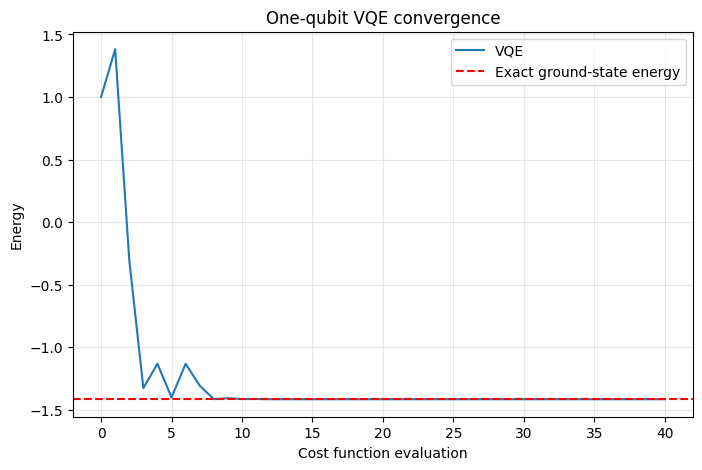

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(energy_history, label="VQE")
plt.axhline(
    -np.sqrt(2),
    linestyle="--",
    color="red",
    label="Exact ground-state energy"
)

plt.xlabel("Cost function evaluation")
plt.ylabel("Energy")
plt.title("One-qubit VQE convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

----

In [20]:

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp
from scipy.optimize import minimize

# Physical parameters, expressed as E/h in GHz
EC = 0.25
EJ_over_EC = 40
EJ = EJ_over_EC * EC
ng = 0.0


n_cutoff = 7
charges = np.arange(-n_cutoff, n_cutoff + 1)

def transmon_hamiltonian(charges, EC, EJ, ng):
    diagonal = 4 * EC * (charges - ng)**2

    H = np.diag(diagonal)

    hopping = -EJ / 2

    for i in range(len(charges) - 1):
        H[i, i+1] = hopping
        H[i+1, i] = hopping

    return H

H_charge = transmon_hamiltonian(charges, EC, EJ, ng)

print("Hamiltonian dimension:", H_charge.shape)
print(H_charge)

Hamiltonian dimension: (15, 15)
[[49. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [-5. 36. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -5. 25. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. -5. 16. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. -5.  9. -5.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. -5.  4. -5.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. -5.  1. -5.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0. -5.  0. -5.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0. -5.  1. -5.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0. -5.  4. -5.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0. -5.  9. -5.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0. -5. 16. -5.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. -5. 25. -5.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. -5. 36. -5.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. -5. 49.]]


In [21]:
exact_energies, exact_states = np.linalg.eigh(H_charge)

E0_exact = exact_energies[0]

print("Exact ground-state energy:", E0_exact, "GHz")
print("First excited energy:", exact_energies[1], "GHz")
print("Second excited energy:", exact_energies[2], "GHz")


Exact ground-state energy: -7.828347517111601 GHz
First excited energy: -3.6227658036667414 GHz
Second excited energy: 0.2885708262509847 GHz


In [22]:
n_qubits = 4
dim = 2**n_qubits

padding_energy = exact_energies[-1] + 100.0

H_padded = np.eye(dim) * padding_energy
H_padded[:len(charges), :len(charges)] = H_charge

# Convert matrix into a sum of Pauli operators
H_qubit = SparsePauliOp.from_operator(H_padded)

print("Number of qubits:", n_qubits)
print("Number of Pauli terms:", len(H_qubit))
print(H_qubit)


Number of qubits: 4
Number of Pauli terms: 38
SparsePauliOp(['IIII', 'IIIX', 'IIIZ', 'IIXX', 'IIYY', 'IIZI', 'IIZX', 'IIZZ', 'IXXX', 'IXYY', 'IYXY', 'IYYX', 'IZII', 'IZIX', 'IZIZ', 'IZZI', 'IZZX', 'IZZZ', 'XXXX', 'XXYY', 'XYXY', 'XYYX', 'YXXY', 'YXYX', 'YYXX', 'YYYY', 'ZIII', 'ZIIX', 'ZIIZ', 'ZIZI', 'ZIZX', 'ZIZZ', 'ZZII', 'ZZIX', 'ZZIZ', 'ZZZI', 'ZZZX', 'ZZZZ'],
              coeffs=[26.9256178+0.j, -4.375    +0.j, -5.9256178+0.j, -2.5      +0.j,
 -2.5      +0.j, -6.4256178+0.j, -0.625    +0.j,  6.4256178+0.j,
 -1.25     +0.j,  1.25     -0.j, -1.25     +0.j, -1.25     +0.j,
 -7.4256178+0.j, -0.625    +0.j,  7.4256178+0.j,  9.4256178+0.j,
  0.625    +0.j, -5.4256178+0.j, -0.625    +0.j,  0.625    -0.j,
  0.625    -0.j,  0.625    -0.j, -0.625    +0.j, -0.625    +0.j,
 -0.625    +0.j,  0.625    +0.j, -9.4256178+0.j, -0.625    +0.j,
  9.4256178+0.j, 13.4256178+0.j,  0.625    +0.j, -5.4256178+0.j,
 21.4256178+0.j,  0.625    +0.j, -5.4256178+0.j, -5.4256178+0.j,
 -0.625    +0.j,  5.4256178+

In [23]:

def create_ansatz(n_qubits, layers=3):
    n_params = n_qubits * (layers + 1)
    theta = ParameterVector("theta", n_params)

    qc = QuantumCircuit(n_qubits)

    # Start from the physical charge state |n=0>
    # In our encoding, charge n=0 has basis index 7.
    zero_charge_index = n_cutoff

    for q in range(n_qubits):
        if (zero_charge_index >> q) & 1:
            qc.x(q)

    idx = 0

    for layer in range(layers):
        # Parameterised rotations
        for q in range(n_qubits):
            qc.ry(theta[idx], q)
            idx += 1

        # Entangling gates
        for q in range(n_qubits - 1):
            qc.cx(q, q + 1)

    # Final rotation layer
    for q in range(n_qubits):
        qc.ry(theta[idx], q)
        idx += 1

    return qc, theta


ansatz, theta = create_ansatz(n_qubits, layers=3)

print(ansatz.draw("text"))
print("Number of parameters:", len(theta))

          ┌───┐      ┌──────────────┐     ┌──────────────┐                »
q_0: ─────┤ X ├──────┤ Ry(theta[0]) ├──■──┤ Ry(theta[4]) ├────────────────»
          ├───┤      ├──────────────┤┌─┴─┐└──────────────┘┌──────────────┐»
q_1: ─────┤ X ├──────┤ Ry(theta[1]) ├┤ X ├───────■────────┤ Ry(theta[5]) ├»
          ├───┤      ├──────────────┤└───┘     ┌─┴─┐      └──────────────┘»
q_2: ─────┤ X ├──────┤ Ry(theta[2]) ├──────────┤ X ├─────────────■────────»
     ┌────┴───┴─────┐└──────────────┘          └───┘           ┌─┴─┐      »
q_3: ┤ Ry(theta[3]) ├──────────────────────────────────────────┤ X ├──────»
     └──────────────┘                                          └───┘      »
«                     ┌──────────────┐                                 »
«q_0: ───────■────────┤ Ry(theta[8]) ├────────────────────────■────────»
«          ┌─┴─┐      └──────────────┘┌──────────────┐      ┌─┴─┐      »
«q_1: ─────┤ X ├─────────────■────────┤ Ry(theta[9]) ├──────┤ X ├──────»
«     ┌────┴───┴─────┐  

In [24]:

energy_history = []

def cost_function(parameters):

    # Assign numerical parameters to the circuit
    bound_circuit = ansatz.assign_parameters(
        dict(zip(theta, parameters))
    )

    # Simulate the quantum state
    state = Statevector.from_instruction(bound_circuit)

    # Calculate energy
    energy = np.real(
        state.expectation_value(H_qubit)
    )

    energy_history.append(float(energy))

    return float(energy)


In [27]:

initial_parameters = np.zeros(len(theta))

result = minimize(
    fun=cost_function,
    x0=initial_parameters,
    method="COBYLA",
    options={
        "maxiter": 10000,
        "rhobeg": 0.3,
        "tol": 1e-7
    }
)

E0_vqe = result.fun

print("VQE ground-state energy:", E0_vqe)
print("Exact ground-state energy:", E0_exact)
print("Absolute error:", abs(E0_vqe - E0_exact))
print("Optimiser success:", result.success)

VQE ground-state energy: -7.7188735260273305
Exact ground-state energy: -7.828347517111601
Absolute error: 0.10947399108427014
Optimiser success: False


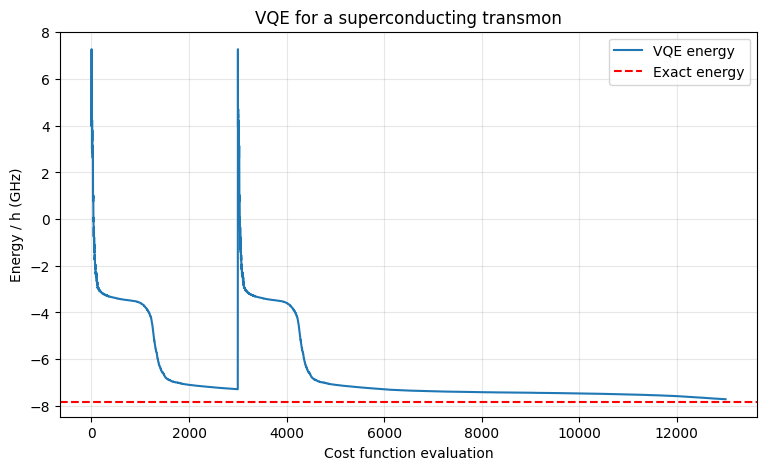

In [28]:

plt.figure(figsize=(9, 5))

plt.plot(energy_history, label="VQE energy")

plt.axhline(
    E0_exact,
    color="red",
    linestyle="--",
    label="Exact energy"
)

plt.xlabel("Cost function evaluation")
plt.ylabel("Energy / h (GHz)")
plt.title("VQE for a superconducting transmon")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [29]:

# Retrieve optimised VQE parameters
theta_0 = result.x.copy()

# Build optimised circuit
ground_circuit = ansatz.assign_parameters(
    dict(zip(theta, theta_0))
)

# Obtain ground-state vector
psi_0 = Statevector.from_instruction(
    ground_circuit
).data

print("Ground-state energy:", E0_vqe)
print("Statevector dimension:", len(psi_0))

Ground-state energy: -7.7188735260273305
Statevector dimension: 16


In [30]:

def get_state(parameters):
    bound_circuit = ansatz.assign_parameters(
        dict(zip(theta, parameters))
    )

    return Statevector.from_instruction(
        bound_circuit
    ).data


def overlap_squared(psi_a, psi_b):
    return float(
        np.abs(np.vdot(psi_a, psi_b))**2
    )

In [31]:

def vqd_cost(
    parameters,
    previous_states,
    beta
):
    # Prepare candidate state
    psi = get_state(parameters)

    # Calculate physical energy
    energy = float(
        np.real(np.vdot(psi, H_qubit.to_matrix() @ psi))
    )

    # Calculate overlap penalties
    penalty = 0.0

    for previous_state in previous_states:
        overlap = overlap_squared(
            previous_state,
            psi
        )
        penalty += beta * overlap

    return energy + penalty

In [32]:

beta = 20.0

rng = np.random.default_rng(42)

initial_theta_1 = rng.uniform(
    -np.pi,
    np.pi,
    len(theta)
)

history_1 = []

def cost_first_excited(parameters):
    cost = vqd_cost(
        parameters,
        previous_states=[psi_0],
        beta=beta
    )

    history_1.append(cost)
    return cost


result_1 = minimize(
    cost_first_excited,
    x0=initial_theta_1,
    method="COBYLA",
    options={
        "maxiter": 5000,
        "rhobeg": 0.3,
        "tol": 1e-7
    }
)

theta_1 = result_1.x
psi_1 = get_state(theta_1)

# Physical energy (without penalty)
E1_vqd = float(
    np.real(np.vdot(psi_1, H_qubit.to_matrix() @ psi_1))
)

In [33]:

initial_theta_2 = rng.uniform(
    -np.pi,
    np.pi,
    len(theta)
)

history_2 = []

def cost_second_excited(parameters):
    cost = vqd_cost(
        parameters,
        previous_states=[psi_0, psi_1],
        beta=beta
    )

    history_2.append(cost)
    return cost


result_2 = minimize(
    cost_second_excited,
    x0=initial_theta_2,
    method="COBYLA",
    options={
        "maxiter": 5000,
        "rhobeg": 0.3,
        "tol": 1e-7
    }
)

theta_2 = result_2.x
psi_2 = get_state(theta_2)

E2_vqd = float(
    np.real(np.vdot(psi_2, H_qubit.to_matrix() @ psi_2))
)

print("Second excited energy (VQD):", E2_vqd)
print("Second excited energy (exact):", exact_energies[2])

print("Overlap with ground state:",
      overlap_squared(psi_0, psi_2))

print("Overlap with first excited state:",
      overlap_squared(psi_1, psi_2))

Second excited energy (VQD): 0.10789494388338694
Second excited energy (exact): 0.2885708262509847
Overlap with ground state: 0.0002575033684503625
Overlap with first excited state: 0.0018375731761057837


In [34]:

import pandas as pd

comparison = pd.DataFrame({
    "State": ["Ground", "First excited", "Second excited"],
    "Exact (GHz)": exact_energies[:3],
    "VQE/VQD (GHz)": [E0_vqe, E1_vqd, E2_vqd]
})

comparison["Absolute error (GHz)"] = np.abs(
    comparison["VQE/VQD (GHz)"] -
    comparison["Exact (GHz)"]
)

print(comparison.to_string(index=False))


         State  Exact (GHz)  VQE/VQD (GHz)  Absolute error (GHz)
        Ground    -7.828348      -7.718874              0.109474
 First excited    -3.622766      -3.149956              0.472810
Second excited     0.288571       0.107895              0.180676
